# Assignment 05: Problem 02
## MNIST Class Implementation and Testing

In Problem 02, we will be implementing a MNIST Class to train and test handwritten numbers from 0-9. Accuracy in evaluating the numbers will be the primary measurement for success.

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import re

from PIL import Image, ImageOps
from pathlib import Path
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense

In [26]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train_ready = (x_train.astype(np.float32) / 255.0)[..., np.newaxis]
x_test_ready = (x_test.astype(np.float32) / 255.0)[..., np.newaxis]

print("Training input shape:", x_train_ready.shape)
print("Testing input shape:", x_test_ready.shape)

Training input shape: (60000, 28, 28, 1)
Testing input shape: (10000, 28, 28, 1)


In [27]:
class Mnist:
    def __init__(self, model_path: str | Path | None = None):
        # Load an existing trained model when a path is provided.
        if model_path is not None:
            self.model = tf.keras.models.load_model(str(model_path))
            return

        # Otherwise, create a new, untrained network.
        self.model = tf.keras.Sequential([
            tf.keras.Input(shape=(28, 28, 1)),
            tf.keras.layers.Flatten(),
            tf.keras.layers.Dense(128, activation="relu"),
            tf.keras.layers.Dense(10, activation="softmax")
        ])

        self.model.compile(
            optimizer="adam",
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

    def train(
        self,
        images: np.ndarray,
        labels: np.ndarray,
        epochs: int = 5
    ):
        """Train using normalized images and integer digit labels."""
        return self.model.fit(
            images,
            labels,
            epochs=epochs,
            batch_size=32,
            validation_split=0.1,
            verbose=1
        )

    def predict(self, input_data: np.ndarray) -> np.ndarray:
        """Perform forward propagation and return the class scores."""
        return self.model.predict(input_data, verbose=0)

    def load_image(
        self,
        image_path: str | Path,
        invert: bool = False
    ) -> np.ndarray:
        """Prepare one handwritten image for inference."""
        image_path = Path(image_path)

        with Image.open(image_path) as original:
            if original.size != (28, 28):
                raise ValueError(
                    f"{image_path.name} has size {original.size}. "
                    "Use a resized 28 x 28 image."
                )

            image = original.convert("L")

        # Use this for dark handwriting on a light background.
        if invert:
            image = ImageOps.invert(image)

        # Match the normalization used for training.
        image_array = np.asarray(image, dtype=np.float32) / 255.0

        # Shape: one image, 28 rows, 28 columns, one channel.
        return image_array.reshape(1, 28, 28, 1)

    def test_image(
        self,
        image_path: str | Path,
        invert: bool = False
    ) -> bool:
        """Display an image and report whether its prediction is correct."""
        image_path = Path(image_path)

        # Check the assignment's filename format.
        match = re.fullmatch(r"([0-9])_([1-5])\.png", image_path.name)

        if match is None:
            raise ValueError(
                f"Invalid filename: {image_path.name}. "
                "Expected a name such as 2_1.png."
            )

        expected_digit = int(match.group(1))

        # The filename is used for checking the answer, not prediction.
        input_data = self.load_image(image_path, invert=invert)
        scores = self.predict(input_data)[0]
        predicted_digit = int(np.argmax(scores))

        # Display the actual image data passed into the model.
        plt.figure(figsize=(3, 3))
        plt.imshow(
            input_data[0, :, :, 0],
            cmap="gray",
            vmin=0,
            vmax=1
        )
        plt.title(
            f"{image_path.name}\n"
            f"Expected: {expected_digit} | Predicted: {predicted_digit}"
        )
        plt.axis("off")
        plt.show()
        plt.close()

        correct = predicted_digit == expected_digit

        if correct:
            print(
                f"Success: Image {image_path.name} is for digit "
                f"{expected_digit} is recognized as {predicted_digit}"
            )
        else:
            print(
                f"Fail: Image {image_path.name} is for digit "
                f"{expected_digit} but the inference result is "
                f"{predicted_digit}"
            )

        return correct

In [28]:
tf.keras.utils.set_random_seed(42)

classifier = Mnist()

classifier.model.summary()

history = classifier.train(
    x_train_ready,
    y_train,
    epochs=5
)

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_1 (Flatten)         (None, 784)               0         
                                                                 
 dense_2 (Dense)             (None, 128)               100480    
                                                                 
 dense_3 (Dense)             (None, 10)                1290      
                                                                 
Total params: 101770 (397.54 KB)
Trainable params: 101770 (397.54 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
Epoch 1/5
1688/1688 [==============================] - 2s 962us/step - loss: 0.2672 - accuracy: 0.9239 - val_loss: 0.1248 - val_accuracy: 0.9632
Epoch 2/5
1688/1688 [==============================] - 2s 934us/step - loss: 0.1179 - accuracy: 0.9650 - val_loss: 0.1031 - val_accur

In [33]:
test_loss, test_accuracy = classifier.model.evaluate(
    x_test_ready,
    y_test,
    verbose=0
)

print(f"MNIST test loss: {test_loss:.4f}")
print(f"MNIST test accuracy: {test_accuracy:.2%}")

# Save the trained model separately from the Rock-Paper-Scissors model.
model_folder = Path("mnist_model")
model_folder.mkdir(exist_ok=True)

model_path = model_folder / "model.keras"
classifier.model.save(str(model_path))

print("Saved model to:", model_path)

MNIST test loss: 0.0698
MNIST test accuracy: 97.77%
Saved model to: mnist_model\model.keras


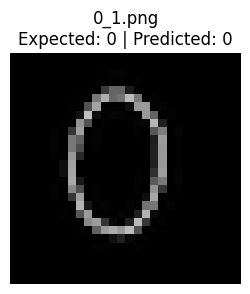

Success: Image 0_1.png is for digit 0 is recognized as 0


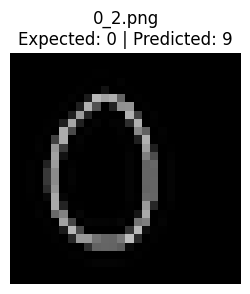

Fail: Image 0_2.png is for digit 0 but the inference result is 9


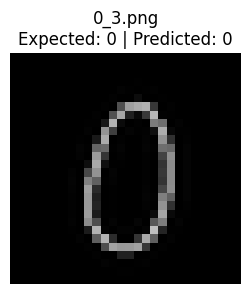

Success: Image 0_3.png is for digit 0 is recognized as 0


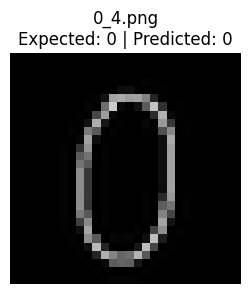

Success: Image 0_4.png is for digit 0 is recognized as 0


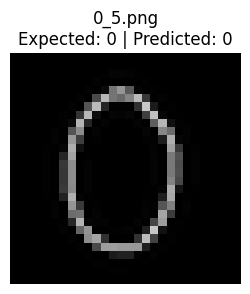

Success: Image 0_5.png is for digit 0 is recognized as 0


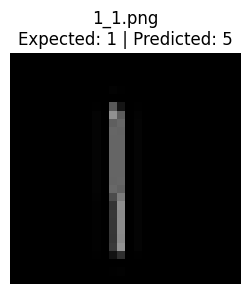

Fail: Image 1_1.png is for digit 1 but the inference result is 5


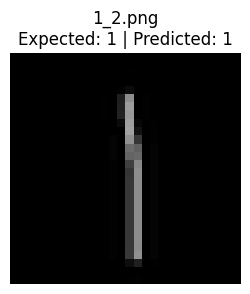

Success: Image 1_2.png is for digit 1 is recognized as 1


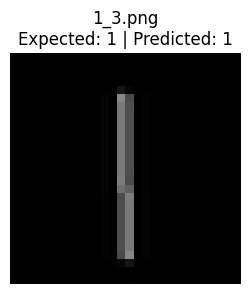

Success: Image 1_3.png is for digit 1 is recognized as 1


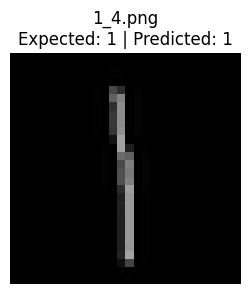

Success: Image 1_4.png is for digit 1 is recognized as 1


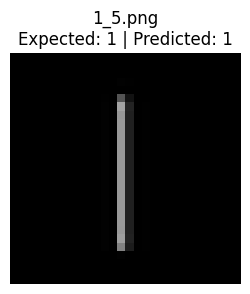

Success: Image 1_5.png is for digit 1 is recognized as 1


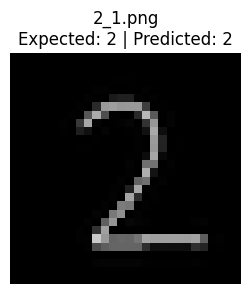

Success: Image 2_1.png is for digit 2 is recognized as 2


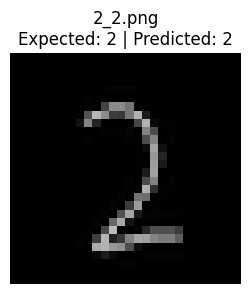

Success: Image 2_2.png is for digit 2 is recognized as 2


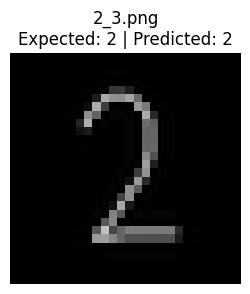

Success: Image 2_3.png is for digit 2 is recognized as 2


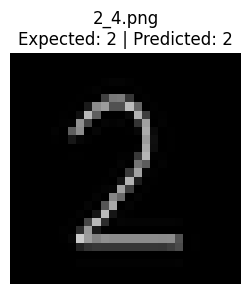

Success: Image 2_4.png is for digit 2 is recognized as 2


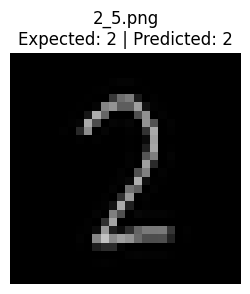

Success: Image 2_5.png is for digit 2 is recognized as 2


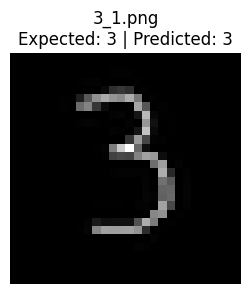

Success: Image 3_1.png is for digit 3 is recognized as 3


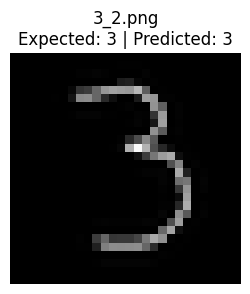

Success: Image 3_2.png is for digit 3 is recognized as 3


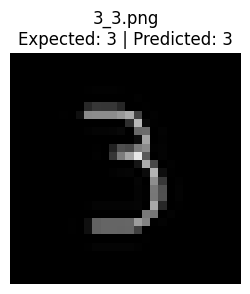

Success: Image 3_3.png is for digit 3 is recognized as 3


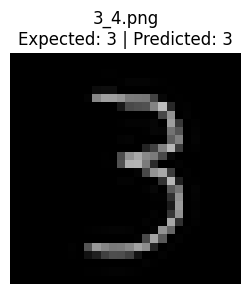

Success: Image 3_4.png is for digit 3 is recognized as 3


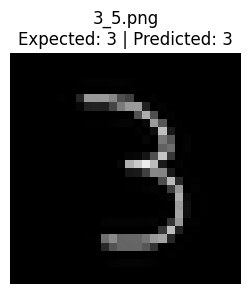

Success: Image 3_5.png is for digit 3 is recognized as 3


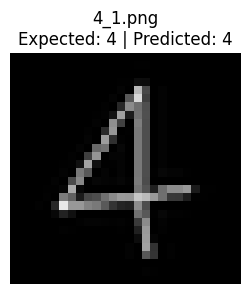

Success: Image 4_1.png is for digit 4 is recognized as 4


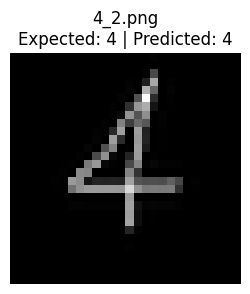

Success: Image 4_2.png is for digit 4 is recognized as 4


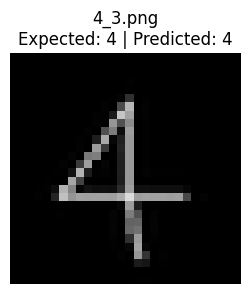

Success: Image 4_3.png is for digit 4 is recognized as 4


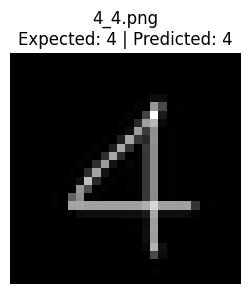

Success: Image 4_4.png is for digit 4 is recognized as 4


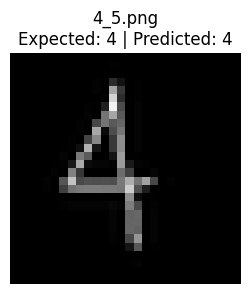

Success: Image 4_5.png is for digit 4 is recognized as 4


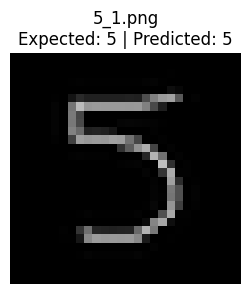

Success: Image 5_1.png is for digit 5 is recognized as 5


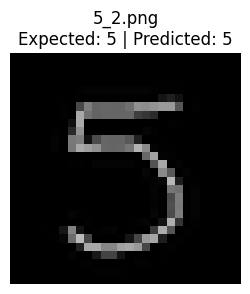

Success: Image 5_2.png is for digit 5 is recognized as 5


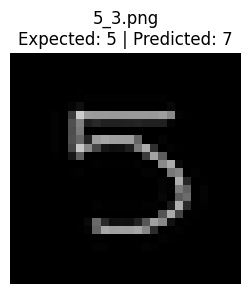

Fail: Image 5_3.png is for digit 5 but the inference result is 7


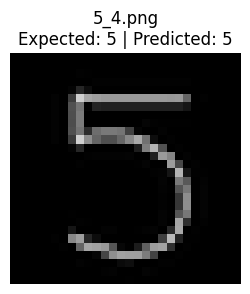

Success: Image 5_4.png is for digit 5 is recognized as 5


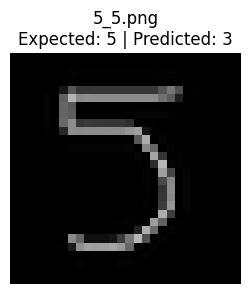

Fail: Image 5_5.png is for digit 5 but the inference result is 3


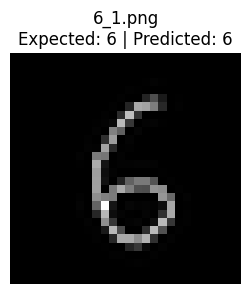

Success: Image 6_1.png is for digit 6 is recognized as 6


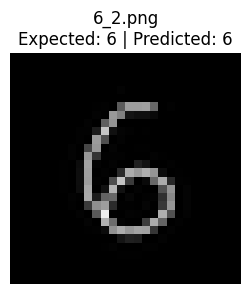

Success: Image 6_2.png is for digit 6 is recognized as 6


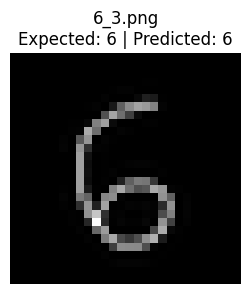

Success: Image 6_3.png is for digit 6 is recognized as 6


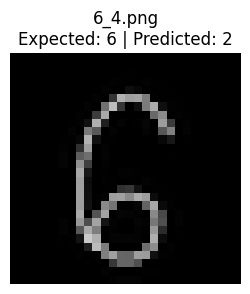

Fail: Image 6_4.png is for digit 6 but the inference result is 2


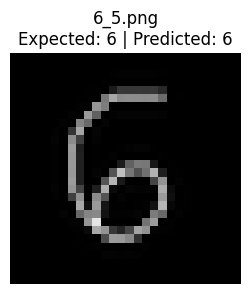

Success: Image 6_5.png is for digit 6 is recognized as 6


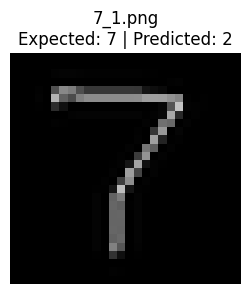

Fail: Image 7_1.png is for digit 7 but the inference result is 2


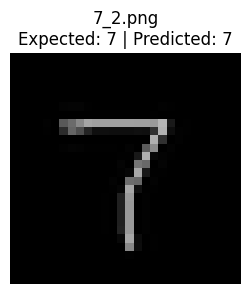

Success: Image 7_2.png is for digit 7 is recognized as 7


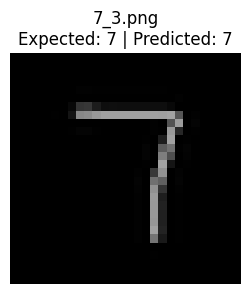

Success: Image 7_3.png is for digit 7 is recognized as 7


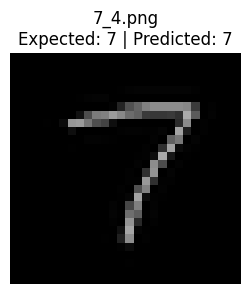

Success: Image 7_4.png is for digit 7 is recognized as 7


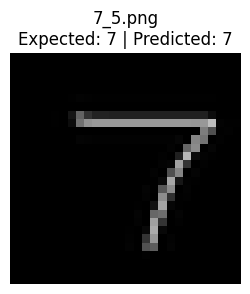

Success: Image 7_5.png is for digit 7 is recognized as 7


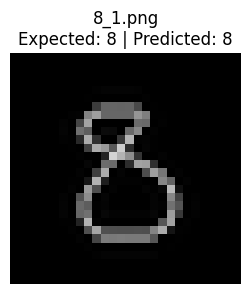

Success: Image 8_1.png is for digit 8 is recognized as 8


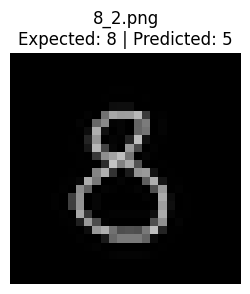

Fail: Image 8_2.png is for digit 8 but the inference result is 5


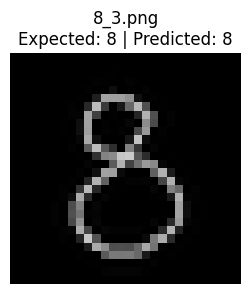

Success: Image 8_3.png is for digit 8 is recognized as 8


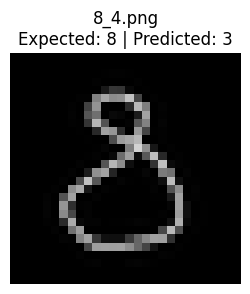

Fail: Image 8_4.png is for digit 8 but the inference result is 3


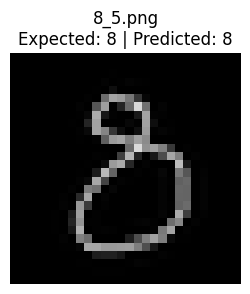

Success: Image 8_5.png is for digit 8 is recognized as 8


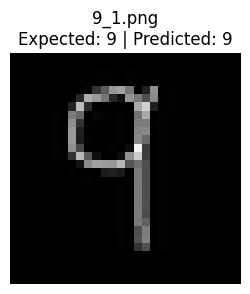

Success: Image 9_1.png is for digit 9 is recognized as 9


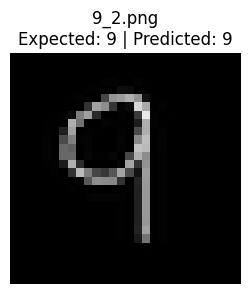

Success: Image 9_2.png is for digit 9 is recognized as 9


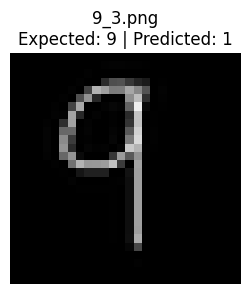

Fail: Image 9_3.png is for digit 9 but the inference result is 1


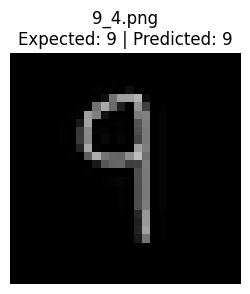

Success: Image 9_4.png is for digit 9 is recognized as 9


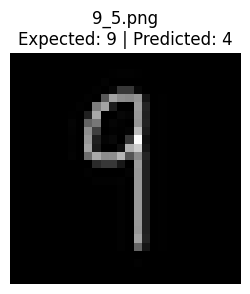

Fail: Image 9_5.png is for digit 9 but the inference result is 4

Handwritten Image Results
-------------------------
Images tested: 50
Successes: 40
Failures: 10
Accuracy: 80.00%


In [34]:
image_folder = Path("images")

# Build the exact list of files required by the assignment.
image_paths = [
    image_folder / f"{digit}_{version}.png"
    for digit in range(10)
    for version in range(1, 6)
]

# Do not silently skip missing assignment images.
missing_files = [
    path.name
    for path in image_paths
    if not path.is_file()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing images in {image_folder.resolve()}:\n"
        + "\n".join(missing_files)
    )

successes = 0

for image_path in image_paths:
    correct = classifier.test_image(
        image_path,
        invert=INVERT_IMAGES
    )

    if correct:
        successes += 1

total = len(image_paths)
failures = total - successes

print("\nHandwritten Image Results")
print("-------------------------")
print(f"Images tested: {total}")
print(f"Successes: {successes}")
print(f"Failures: {failures}")
print(f"Accuracy: {successes / total:.2%}")

## Results

The trained model achieved 97.77% accuracry on the standard MNIST test set. For the 50 handwritten test images, the model correctly classified 40 images and misclassified 10 resulting in 80% accuracy.